# Heart Disease Prediction — Model Evaluation

The model selected in training is evaluated **once** on the 184 held-out test patients.

In screening, the two kinds of mistakes are not equal:
- **False negative** — a sick patient is told they are fine → dangerous
- **False positive** — a healthy patient is sent for more tests → inconvenient

So instead of the default 0.5 cut-off, we pick the threshold that reaches **≥ 90% recall**, using cross-validated predictions on the **training set** (choosing it on the test set would leak information).

Evaluation code: [`src/evaluate.py`](../src/evaluate.py)

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.calibration import calibration_curve
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, precision_recall_curve

from src.preprocess import load_data
from src.evaluate import (
    TARGET_RECALL, choose_threshold, compute_metrics, load_model, out_of_fold_proba,
)

sns.set_theme(style="whitegrid")

In [2]:
X_train, X_test, y_train, y_test = load_data()
model, metadata = load_model()
print("Model:", metadata["model_name"], "| params:", metadata["best_params"])

Model: Logistic Regression | params: {'C': 0.1}


## 1. Choosing the threshold (training set, cross-validated)

In [3]:
oof_proba = out_of_fold_proba(model, X_train, y_train)
threshold = choose_threshold(y_train, oof_proba)
print(f"Threshold that gives >= {TARGET_RECALL:.0%} recall on training CV: {threshold:.3f}")

Threshold that gives >= 90% recall on training CV: 0.407


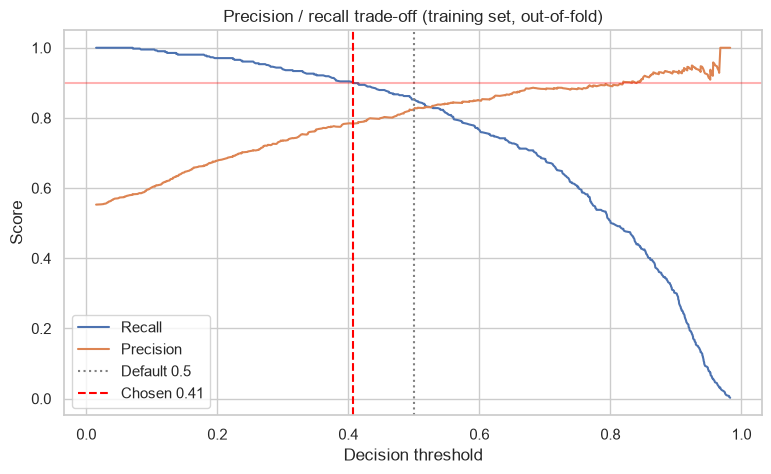

In [4]:
precision, recall, thr = precision_recall_curve(y_train, oof_proba)

plt.figure(figsize=(9, 5))
plt.plot(thr, recall[:-1], label="Recall")
plt.plot(thr, precision[:-1], label="Precision")
plt.axvline(0.5, color="gray", linestyle=":", label="Default 0.5")
plt.axvline(threshold, color="red", linestyle="--", label=f"Chosen {threshold:.2f}")
plt.axhline(TARGET_RECALL, color="red", alpha=0.3)
plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.title("Precision / recall trade-off (training set, out-of-fold)")
plt.legend()
plt.show()

Lowering the threshold flags more patients as at-risk: recall goes up, precision goes down. The chosen threshold is the highest one that still keeps recall at 90%.

## 2. Test set results

In [5]:
test_proba = model.predict_proba(X_test)[:, 1]
default = compute_metrics(y_test, test_proba, 0.5)
tuned = compute_metrics(y_test, test_proba, threshold)

rows = ["roc_auc", "recall", "precision", "f1", "accuracy", "specificity", "false_negatives", "false_positives"]
pd.DataFrame({"Threshold 0.5": default, f"Threshold {threshold:.2f}": tuned}).loc[rows].round(3)

,Threshold 0.5,Threshold 0.41
roc_auc,0.904,0.904
recall,0.853,0.922
precision,0.821,0.783
f1,0.837,0.847
accuracy,0.815,0.815
specificity,0.768,0.683
false_negatives,15.000,8.000
false_positives,19.000,26.000


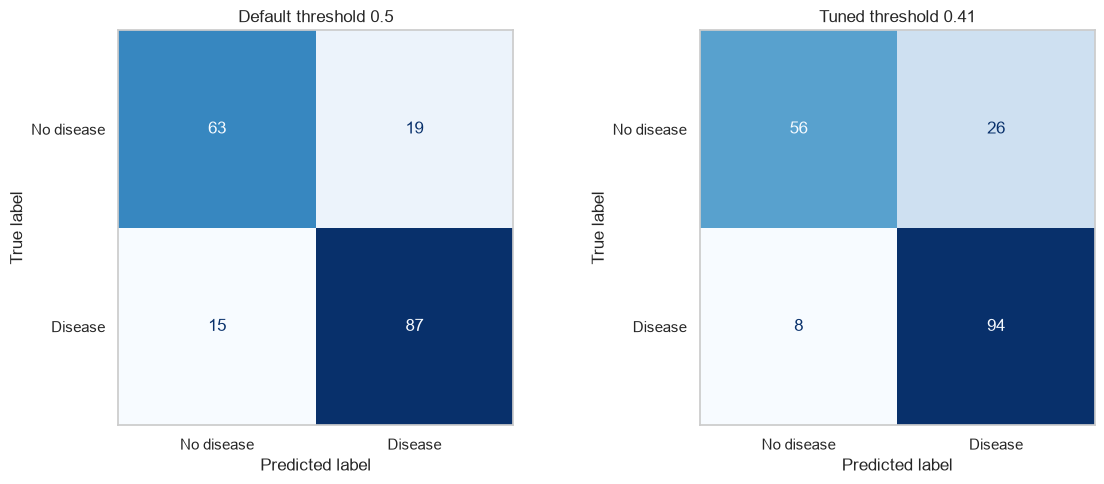

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, t, title in [(axes[0], 0.5, "Default threshold 0.5"), (axes[1], threshold, f"Tuned threshold {threshold:.2f}")]:
    ConfusionMatrixDisplay.from_predictions(
        y_test, (test_proba >= t).astype(int),
        display_labels=["No disease", "Disease"], cmap="Blues", ax=ax, colorbar=False,
    )
    ax.set_title(title)
    ax.grid(False)
plt.tight_layout()
plt.show()

The tuned threshold catches more sick patients (fewer false negatives, bottom-left) at the cost of a few more false alarms (top-right) — the right trade-off for a screening tool.

## 3. ROC curve

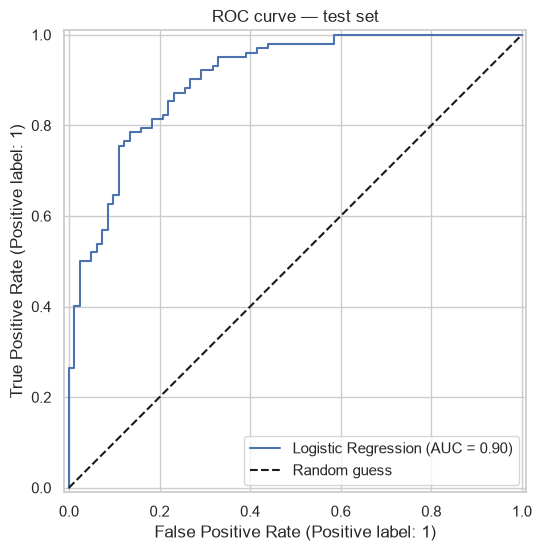

In [7]:
fig, ax = plt.subplots(figsize=(6, 6))
RocCurveDisplay.from_predictions(y_test, test_proba, name=metadata["model_name"], ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.set_title("ROC curve — test set")
ax.legend()
plt.show()

## 4. Are the probabilities trustworthy? (calibration)

The app will show a **risk probability**, so a predicted 70% should mean roughly 70% of such patients actually have disease. Points close to the diagonal = well calibrated.

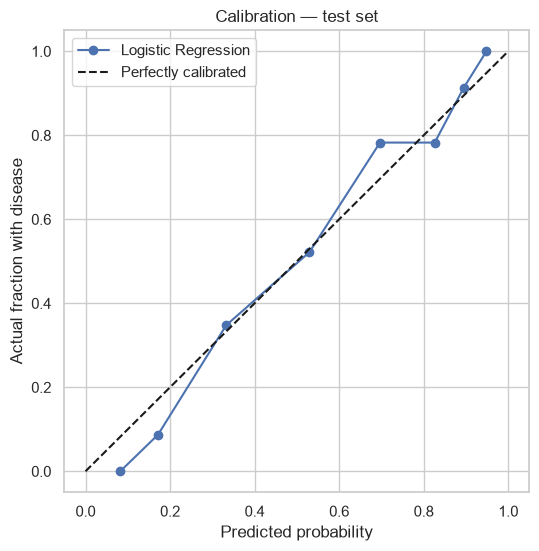

In [8]:
frac_pos, mean_pred = calibration_curve(y_test, test_proba, n_bins=8, strategy="quantile")

plt.figure(figsize=(6, 6))
plt.plot(mean_pred, frac_pos, "o-", label=metadata["model_name"])
plt.plot([0, 1], [0, 1], "k--", label="Perfectly calibrated")
plt.xlabel("Predicted probability")
plt.ylabel("Actual fraction with disease")
plt.title("Calibration — test set")
plt.legend()
plt.show()

## 5. CV vs test — any overfitting?

In [9]:
pd.DataFrame({
    "Cross-validation (train)": metadata["cv_scores"],
    "Test (threshold 0.5)": {k: default[k] for k in metadata["cv_scores"]},
}).round(3)

,Cross-validation (train),Test (threshold 0.5)
roc_auc,0.883,0.904
recall,0.852,0.853
precision,0.829,0.821
f1,0.839,0.837
accuracy,0.819,0.815


## Summary

- **Test ROC-AUC ≈ 0.90**, in line with cross-validation (≈ 0.88) → the model generalises; no sign of overfitting.
- With the recall-oriented threshold, the model catches **~92% of sick patients** in the test set, roughly halving the missed cases compared with the default 0.5.
- The cost is more false alarms (lower specificity) — acceptable for a screening tool, where a positive result means *"get checked"*, not a diagnosis.
- The chosen threshold and test metrics are stored in `models/model_metadata.json` (written by `python -m src.evaluate`), so the app uses the same cut-off.

**Limitations:** small dataset (920 patients from 4 hospitals, collected decades ago), `ca`/`thal` excluded, and the test set has only 184 patients — so the scores have a few points of uncertainty. This is a demonstration project, not a medical device.